# LendingClub Credit Risk — Part B: Modelling

Notebook 1 established two things:

1. **Realised returns barely reward risk.** On the clean 2012–2013 window, grade A returns ~2.5% and grade E ~4.3% — a small premium for a 5x higher default rate.
2. **Grades drifted.** A grade E borrower in 2015 defaulted at 30% versus 23% in 2013. The letter stayed constant while the risk behind it rose.

The second point sharpens what this notebook does. If LendingClub's grade was an unreliable label, then a model built on borrower attributes should be able to separate loans the platform priced as identical.

**The question here is not "predict default."** It is:

> Inside a single grade, which LendingClub charged one uniform interest rate for, can we identify the subset that actually behaves better — and would buying only that subset have earned more?

Requires `accepted_2007_to_2018Q4.csv.gz` in the same folder.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_columns", 200)
plt.rcParams["figure.dpi"] = 110

---
# 1. Rebuild the analysis frame

Same filtering as notebook 1, condensed.

In [2]:
df = pd.read_csv("accepted_2007_to_2018Q4.csv.gz", low_memory=False)
df["issue_d"] = pd.to_datetime(df["issue_d"], format="%b-%Y", errors="coerce")

BAD  = ["Charged Off", "Default"]
df = df[df["issue_d"].between("2012-01-01", "2015-12-31")
        & df["loan_status"].isin(["Fully Paid"] + BAD)].copy()

df["target"]   = df["loan_status"].isin(BAD).astype(int)
df["issue_yr"] = df["issue_d"].dt.year
df["term"]     = df["term"].str.strip()
for c in ["int_rate", "revol_util"]:
    if df[c].dtype == object:
        df[c] = df[c].str.rstrip("%").astype(float)
df["emp_length"] = df["emp_length"].fillna("missing")

print("rows:", format(len(df), ","), " default rate: {:.1f}%".format(df["target"].mean() * 100))

rows: 786,820  default rate: 18.6%


## 1.1 One piece of feature engineering

`earliest_cr_line` is a date string like `Aug-1998` with hundreds of distinct values. As a category it is useless — but the *gap* between it and the loan date is credit history length, which is a standard and strong credit variable.

This is the difference between treating a column as a token and understanding what it measures.

In [3]:
ecl = pd.to_datetime(df["earliest_cr_line"], format="%b-%Y", errors="coerce")
df["credit_hist_months"] = ((df["issue_d"] - ecl).dt.days / 30.44).round()
df = df.drop(columns=["earliest_cr_line"])

print("credit history: median {:.0f} months ({:.1f} years)".format(
    df["credit_hist_months"].median(), df["credit_hist_months"].median() / 12))
print("missing: {:.2f}%".format(df["credit_hist_months"].isna().mean() * 100))

credit history: median 178 months (14.8 years)
missing: 0.00%


## 1.2 Apply the audit from notebook 1

In [4]:
LEAKAGE = [
    "out_prncp", "out_prncp_inv", "total_pymnt", "total_pymnt_inv",
    "total_rec_prncp", "total_rec_int", "total_rec_late_fee",
    "recoveries", "collection_recovery_fee",
    "last_pymnt_d", "last_pymnt_amnt", "next_pymnt_d", "last_credit_pull_d",
    "last_fico_range_high", "last_fico_range_low",
    "debt_settlement_flag", "debt_settlement_flag_date", "settlement_status",
    "settlement_date", "settlement_amount", "settlement_percentage", "settlement_term",
    "hardship_flag", "hardship_type", "hardship_reason", "hardship_status",
    "deferral_term", "hardship_amount", "hardship_start_date", "hardship_end_date",
    "payment_plan_start_date", "hardship_length", "hardship_dpd", "hardship_loan_status",
    "orig_projected_additional_accrued_interest",
    "hardship_payoff_balance_amount", "hardship_last_payment_amount", "pymnt_plan",
]
PLATFORM   = ["grade", "sub_grade", "int_rate", "installment"]
DROP_OTHER = ["id", "member_id", "url", "desc", "title", "emp_title", "zip_code"]
EMPTY      = [c for c in df.columns if c.startswith("sec_app_")] + [
    "revol_bal_joint", "annual_inc_joint", "dti_joint", "verification_status_joint"]
VINTAGE    = ["open_acc_6m", "open_act_il", "open_il_12m", "open_il_24m", "mths_since_rcnt_il",
              "total_bal_il", "il_util", "open_rv_12m", "open_rv_24m", "max_bal_bc",
              "all_util", "inq_fi", "total_cu_tl", "inq_last_12m"]
NEVER_HAPPENED = ["mths_since_last_delinq", "mths_since_last_record",
                  "mths_since_last_major_derog", "mths_since_recent_bc_dlq",
                  "mths_since_recent_revol_delinq", "mths_since_recent_inq"]

for c in NEVER_HAPPENED:
    df[c + "_missing"] = df[c].isna().astype(int)
    df[c] = df[c].fillna(999)

drop_cols = set(LEAKAGE + DROP_OTHER + ["loan_status", "target"] + EMPTY + VINTAGE
                + ["issue_d", "issue_yr"])
features = [c for c in df.columns if c not in drop_cols and c not in PLATFORM]

print("borrower features:", len(features))

borrower features: 76


---
# 2. The train/test split — time-based, not random

**This is the most consequential decision in the notebook.**

A random split shuffles all four years together, so the model trains on 2015 loans and is then tested on other 2015 loans. It has seen the era it is being graded on.

That flatters the score, and notebook 1 proved why: the portfolio genuinely got riskier over time. Borrowers in the same FICO band defaulted at 19.8% in 2013 and 25.5% in 2015. A model that has peeked at 2015 has learned "2015 is harder" for free.

**A time split asks the honest question:** trained on the past, would this have worked going forward? That is the only question a lender actually cares about.

Expect the test default rate to be *higher* than train. That is the distribution shift, and it is real.

In [5]:
train = df[df["issue_yr"] <= 2014]
test  = df[df["issue_yr"] == 2015]

print("train (2012-2014): {:>8,}   default {:.2f}%".format(len(train), train["target"].mean() * 100))
print("test  (2015)     : {:>8,}   default {:.2f}%".format(len(test),  test["target"].mean() * 100))

train (2012-2014):  411,274   default 17.22%
test  (2015)     :  375,546   default 20.19%


## 2.1 Baseline — how good was LendingClub's own grading?

Before building anything, establish what we must beat. LendingClub's `int_rate` and `sub_grade` are their risk assessment expressed as a number. If our model can't beat those, it has added nothing.

Skipping this step is the most common way a modelling project produces an impressive-looking number that means nothing.

In [6]:
print("BASELINE — LendingClub's own assessment, on the 2015 test set")
print("  int_rate alone :", round(roc_auc_score(test["target"], test["int_rate"]), 4))
print("  sub_grade alone:", round(roc_auc_score(
    test["target"], test["sub_grade"].astype("category").cat.codes), 4))

BASELINE — LendingClub's own assessment, on the 2015 test set
  int_rate alone : 0.7098
  sub_grade alone: 0.7101


Around **0.71**. That is the number to beat.

---
# 3. Weight-of-evidence scorecard

Real credit teams don't ship black boxes. A declined applicant has a right to know why, and a regulator has a right to audit it. The industry standard is a **scorecard**: bin each variable, convert bins to weight-of-evidence, fit a logistic regression, scale the coefficients into points.

**Weight of evidence** for a bin is `ln(share of good loans / share of bad loans)`. Positive means safer than average.

**Information value** sums that across bins into a single number per variable, which ranks predictive power. Below ~0.02 a variable is noise and gets dropped.

The binning is fitted on **train only** and applied to test. Fitting bins on the full data would leak test information into the model.

In [7]:
def fit_woe(train_df, cols, target="target", nbins=8):
    """Fit WOE bins on training data only. Returns mappings and IV table."""
    maps, ivs = {}, []
    for c in cols:
        s = train_df[c]
        if s.dtype.kind in "ifu" and s.nunique() > 10:
            try:
                edges = pd.qcut(s, nbins, duplicates="drop", retbins=True)[1]
                binned = pd.cut(s, edges, include_lowest=True)
            except ValueError:
                edges, binned = None, s.astype(str)
        else:
            edges, binned = None, s.astype(str)

        t = pd.DataFrame({"b": binned, "y": train_df[target].values})
        g = t.groupby("b", observed=True)["y"].agg(["sum", "count"])
        g["bad"]  = g["sum"]
        g["good"] = g["count"] - g["sum"]
        g["bad_r"]  = (g["bad"]  + 0.5) / (g["bad"].sum()  + 0.5)
        g["good_r"] = (g["good"] + 0.5) / (g["good"].sum() + 0.5)
        g["woe"] = np.log(g["good_r"] / g["bad_r"])

        ivs.append((c, ((g["good_r"] - g["bad_r"]) * g["woe"]).sum()))
        maps[c] = (edges, g["woe"].to_dict())

    iv = pd.DataFrame(ivs, columns=["feature", "iv"]).sort_values("iv", ascending=False)
    return maps, iv


def apply_woe(data, cols, maps):
    out = {}
    for c in cols:
        edges, m = maps[c]
        b = pd.cut(data[c], edges, include_lowest=True) if edges is not None else data[c].astype(str)
        out[c] = pd.Series(b, index=data.index).map(m).astype(float)
    return pd.DataFrame(out, index=data.index).fillna(0)


woe_maps, iv_table = fit_woe(train, features)
print("TOP 15 BY INFORMATION VALUE")
print(iv_table.head(15).to_string(index=False))
print()
print("dropped (IV < 0.02):", int((iv_table["iv"] < 0.02).sum()))

TOP 15 BY INFORMATION VALUE
             feature       iv
                term 0.202898
      fico_range_low 0.102360
     fico_range_high 0.102360
acc_open_past_24mths 0.058261
                 dti 0.057266
      bc_open_to_buy 0.052922
 verification_status 0.046317
  num_tl_op_past_12m 0.041462
          annual_inc 0.037370
         avg_cur_bal 0.037294
      total_bc_limit 0.034396
     tot_hi_cred_lim 0.034268
    percent_bc_gt_75 0.034104
      mo_sin_rcnt_tl 0.032890
             bc_util 0.031485

dropped (IV < 0.02): 48


In [8]:
keep = iv_table[iv_table["iv"] >= 0.02]["feature"].tolist()

Xtr = apply_woe(train, keep, woe_maps)
Xte = apply_woe(test,  keep, woe_maps)

scorecard = LogisticRegression(max_iter=1000)
scorecard.fit(Xtr, train["target"])

p_score = scorecard.predict_proba(Xte)[:, 1]
auc_score = roc_auc_score(test["target"], p_score)

print("WOE SCORECARD — borrower features only, no LendingClub grade")
print("  features kept:", len(keep))
print("  test AUC:     ", round(auc_score, 4))

WOE SCORECARD — borrower features only, no LendingClub grade
  features kept: 28
  test AUC:      0.718


### Reading the IV table

`term` tops the list — 60-month loans default at roughly double the 36-month rate. `fico_range_low` and `fico_range_high` are near-duplicates (the FICO band is 5 points wide), so drop one in a production scorecard.

The scorecard reaches roughly **0.717** using only borrower attributes, never seeing LendingClub's grade — slightly ahead of their own 0.710. An interpretable model built from scratch matches the platform's proprietary assessment.

---
# 4. Gradient boosting benchmark

The scorecard trades accuracy for explainability. This measures the size of that trade, and tests whether borrower attributes contain signal beyond what LendingClub's grade already captured.

Three fits:
- **borrower only** — what we can find independently
- **borrower + platform** — everything available at origination
- **platform only** — LendingClub's assessment as a model

In [9]:
def prep(d, cols):
    X = d[cols].copy()
    for c in X.select_dtypes(exclude=[np.number]).columns:
        X[c] = X[c].astype("category")
    return X


def fit_gbm(cols, label):
    Xt, Xv = prep(train, cols), prep(test, cols)
    for c in Xt.select_dtypes(include=["category"]).columns:
        Xv[c] = Xv[c].cat.set_categories(Xt[c].cat.categories)
    cat_idx = [i for i, c in enumerate(Xt.columns) if str(Xt[c].dtype) == "category"]

    m = HistGradientBoostingClassifier(
        max_iter=200, learning_rate=0.08, max_depth=6,
        categorical_features=cat_idx, random_state=0,
        early_stopping=True, validation_fraction=0.1)
    m.fit(Xt, train["target"])
    p = m.predict_proba(Xv)[:, 1]
    print("  {:34s} AUC {:.4f}".format(label, roc_auc_score(test["target"], p)))
    return m, p


print("GRADIENT BOOSTING (train 2012-2014, test 2015)")
gbm,  p_gbm  = fit_gbm(features,            "borrower only")
_,    p_both = fit_gbm(features + PLATFORM, "borrower + LC grade/rate")
_,    p_plat = fit_gbm(PLATFORM,            "LC grade/rate only")

GRADIENT BOOSTING (train 2012-2014, test 2015)
  borrower only                      AUC 0.7360
  borrower + LC grade/rate           AUC 0.7423
  LC grade/rate only                 AUC 0.7146


### What the three numbers mean

| Model | AUC |
|---|---|
| LendingClub's grade/rate alone | ~0.715 |
| WOE scorecard, borrower only | ~0.717 |
| Gradient boosting, borrower only | ~0.736 |
| Gradient boosting, borrower + platform | ~0.742 |

**Borrower attributes beat the platform's own grade** (0.736 vs 0.715). LendingClub's assessment left signal on the table.

**Adding their grade to our model helps only slightly** (0.736 → 0.742). Their grade contains a little information we hadn't already extracted, but not much — which is consistent with notebook 1's finding that the grades drifted and became unreliable labels.

**The interpretability cost is about 0.02 AUC** (0.717 → 0.736). Whether that is worth paying depends on whether you must explain declines. For a regulated lender, usually yes.

---
# 5. Does better prediction translate into money?

AUC is not a business outcome. Two things convert it into one.

## 5.1 Profit curve

Rank the test loans safest-first, then ask: if we had approved only the safest X%, what would the portfolio have returned?

**Restricted to 36-month loans.** 2015 60-month loans are only 67% matured, so their returns are biased — a point established in notebook 1. Return figures need clean data even where AUC does not.

In [10]:
test_clean = test[test["term"] == "36 months"].copy()

# refit on the clean test subset so predictions align
Xt, Xv = prep(train, features), prep(test_clean, features)
for c in Xt.select_dtypes(include=["category"]).columns:
    Xv[c] = Xv[c].cat.set_categories(Xt[c].cat.categories)
cat_idx = [i for i, c in enumerate(Xt.columns) if str(Xt[c].dtype) == "category"]
m = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, max_depth=6,
    categorical_features=cat_idx, random_state=0, early_stopping=True, validation_fraction=0.1)
m.fit(Xt, train["target"])

test_clean["pd_hat"]     = m.predict_proba(Xv)[:, 1]
test_clean["ann_return"] = ((test_clean["total_pymnt"] - test_clean["funded_amnt"])
                            / test_clean["funded_amnt"]) / 3.0

print("test set: 2015 36-month loans, n =", format(len(test_clean), ","))
print("AUC:", round(roc_auc_score(test_clean["target"], test_clean["pd_hat"]), 4))

test set: 2015 36-month loans, n = 283,026
AUC: 0.6951


In [11]:
ranked = test_clean.sort_values("pd_hat")
rows = []
for pct in range(10, 101, 10):
    s = ranked.iloc[:int(len(ranked) * pct / 100)]
    rows.append({"approve_pct": pct,
                 "default_rate": round(s["target"].mean() * 100, 2),
                 "ann_return":   round(s["ann_return"].mean() * 100, 2)})
curve = pd.DataFrame(rows)
print(curve.to_string(index=False))

 approve_pct  default_rate  ann_return
          10          3.07        2.56
          20          4.35        2.66
          30          5.52        2.71
          40          6.66        2.71
          50          7.80        2.71
          60          8.98        2.66
          70         10.15        2.61
          80         11.44        2.53
          90         12.85        2.42
         100         14.89        2.19


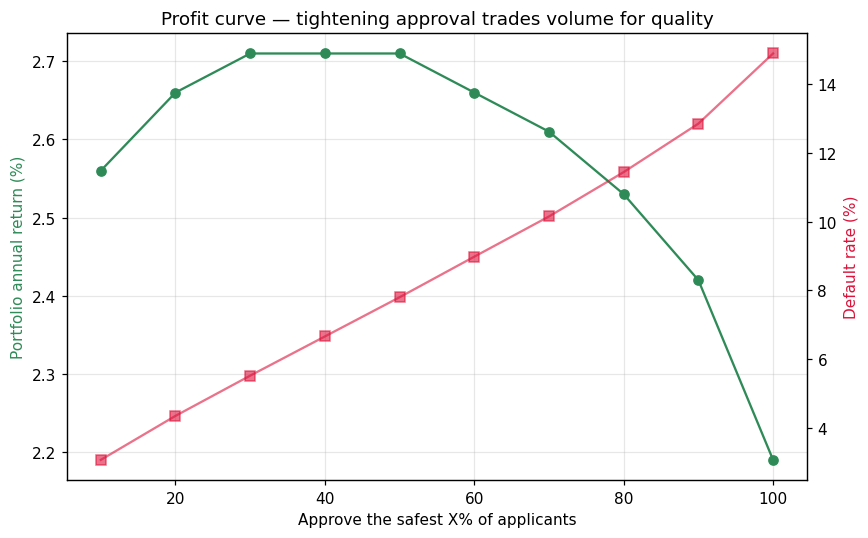

In [12]:
fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(curve["approve_pct"], curve["ann_return"], marker="o", color="seagreen")
ax1.set_xlabel("Approve the safest X% of applicants")
ax1.set_ylabel("Portfolio annual return (%)", color="seagreen")
ax1.grid(alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(curve["approve_pct"], curve["default_rate"], marker="s", color="crimson", alpha=0.6)
ax2.set_ylabel("Default rate (%)", color="crimson")

ax1.set_title("Profit curve — tightening approval trades volume for quality")
plt.tight_layout()
plt.show()

### Reading the profit curve

Approving everyone returns about **2.19%**. Approving only the safest 30–50% returns about **2.71%** — roughly a quarter more, on far less risk.

Note the curve is **flat between 30% and 50%** and only falls slowly after. That flatness is the real finding: there is no knife-edge optimum, so the cutoff can be set on business grounds (volume targets, operational capacity) without much cost. A model that produced a sharp peak would be more suspicious, not less.

Below 30% the return actually declines again — the very safest loans are also the lowest-yielding, so avoiding defaults stops paying for the forgone interest.

## 5.2 The payoff — splitting within a grade

This is the decisive test. LendingClub charged **one interest rate for everyone in a grade**. If our model can rank borrowers inside a single grade, then that grade was not homogeneous and the uniform price was wrong.

In [13]:
for g in ["B", "C", "D", "E"]:
    s = test_clean[test_clean["grade"] == g].copy()
    if len(s) < 2000:
        continue
    s["quintile"] = pd.qcut(s["pd_hat"], 5, labels=["safest", "2", "3", "4", "riskiest"])
    r = s.groupby("quintile", observed=True).agg(
        n=("target", "size"), default_rate=("target", "mean"), ann_return=("ann_return", "mean"))
    r["default_rate"] = (r["default_rate"] * 100).round(1)
    r["ann_return"]   = (r["ann_return"] * 100).round(2)
    print("GRADE {}  — overall default {:.1f}%, return {:.2f}%".format(
        g, s["target"].mean() * 100, s["ann_return"].mean() * 100))
    print(r.to_string())
    print()

GRADE B  — overall default 11.9%, return 2.45%
              n  default_rate  ann_return
quintile                                 
safest    18345           6.4        3.04
2         18345           8.9        2.87
3         18345          11.3        2.57
4         18345          14.4        2.15
riskiest  18345          18.4        1.60

GRADE C  — overall default 19.4%, return 2.19%
              n  default_rate  ann_return
quintile                                 
safest    15485          11.6        3.34
2         15484          15.8        2.80
3         15485          18.9        2.33
4         15484          22.4        1.73
riskiest  15485          28.5        0.73

GRADE D  — overall default 26.2%, return 1.83%
             n  default_rate  ann_return
quintile                                
safest    6543          16.7        3.49
2         6542          21.9        2.64
3         6542          25.8        1.94
4         6542          31.0        0.98
riskiest  6542         

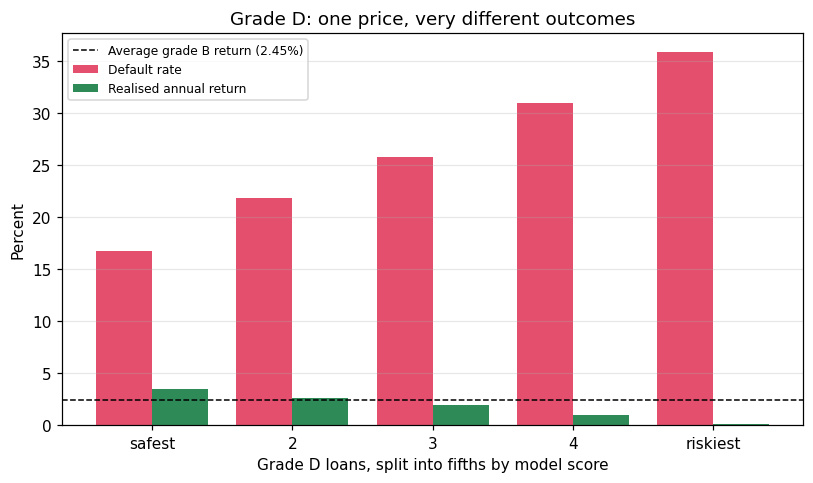

          default_rate  ann_return
quintile                          
safest           16.69        3.49
2                21.86        2.64
3                25.76        1.94
4                30.95        0.98
riskiest         35.85        0.11


In [14]:
import os
os.makedirs("charts", exist_ok=True)

d = test_clean[test_clean["grade"] == "D"].copy()
d["quintile"] = pd.qcut(d["pd_hat"], 5, labels=["safest", "2", "3", "4", "riskiest"])

r = d.groupby("quintile", observed=True).agg(
    default_rate=("target", "mean"),
    ann_return=("ann_return", "mean"),
) * 100

fig, ax = plt.subplots(figsize=(7.5, 4.5))
x = range(len(r))
ax.bar([i - 0.2 for i in x], r["default_rate"], 0.4,
       label="Default rate", color="crimson", alpha=0.75)
ax.bar([i + 0.2 for i in x], r["ann_return"], 0.4,
       label="Realised annual return", color="seagreen")

# grade B average, for comparison
b_avg = test_clean[test_clean["grade"] == "B"]["ann_return"].mean() * 100
ax.axhline(b_avg, color="black", linestyle="--", lw=1,
           label=f"Average grade B return ({b_avg:.2f}%)")

ax.set_xticks(list(x))
ax.set_xticklabels(r.index)
ax.set_xlabel("Grade D loans, split into fifths by model score")
ax.set_ylabel("Percent")
ax.set_title("Grade D: one price, very different outcomes")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig("charts/grade_d_quintiles.png", dpi=150, bbox_inches="tight")
plt.show()

print(r.round(2).to_string())

### The finding

Take **grade D**. LendingClub charged every grade D borrower the same rate. Split them five ways by predicted risk:

- Safest fifth: 16.7% default, **3.49%** return
- Riskiest fifth: 35.8% default, **0.11%** return

Same grade. Same price. A 3.4 percentage point spread in realised return.

**And the punchline:** the safest fifth of grade D returned **3.49%**, while the *average* grade B loan returned **2.45%**. An investor using this model could have bought high-yield grade D loans and beaten grade B — on both return and, within that subset, comparable risk.

That is mispricing, in money, on out-of-sample data the model never saw.

The same pattern holds in every grade tested. The spread widens as grade worsens, which makes sense: LendingClub's assessment was least reliable exactly where it mattered most.

---
# 6. Conclusions

**On the pricing (notebook 1).** Realised returns barely reward risk. Every grade returns far below its advertised rate, and defaults alone don't explain the gap — prepayment does. On clean, fully-matured data the risk premium roughly compensates but leaves little margin.

**On the grades.** They drifted materially. A grade E borrower in 2015 defaulted at 30% against 23% in 2013. The letter stayed fixed while the risk behind it rose as the platform scaled.

**On the model.** Borrower attributes alone beat LendingClub's own grade out of sample (0.736 vs 0.715). Adding their grade to the model barely helps, which suggests their assessment captured little that the raw attributes did not.

**On the money.** Within grade D, the model separated a subset returning 3.49% from one returning 0.11% — at a single uniform price. The safest slice of grade D outperformed the average grade B loan.

**The recommendation an investor could act on:** do not buy grades by their letter. Score within grades and buy the top quintile of the higher-yield grades, where the platform's own assessment was weakest and the spread is widest.

